# 01 - Dataset Analysis and Preparation

**Dataset chosen: African Wildlife** (Ultralytics-hosted, public, real photographs of
buffalo, elephant, rhino and zebra, already annotated with bounding boxes). Chosen because it needs no
account/API key, is small enough for Colab/consumer GPUs, has several real-world classes,
and is close to YOLO format.

This notebook: downloads it, inspects it (do **not** assume it is perfect), validates
images/labels, builds the clean YOLO structure and writes `dataset.yaml`.

In [1]:
import sys
from pathlib import Path

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from common import *
print("Project root:", ROOT)

Project root: C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection


## 1. Download and extract (terminal-equivalent, no credentials)

In [2]:
from download_dataset import download, extract
raw = extract(download())

Already downloaded: C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection\data\raw\kitti.zip
Already extracted: C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection\data\raw\kitti


## 2. Inspect directory structure

In [3]:
def tree(path, depth=0, max_depth=3, max_items=6):
    items = sorted(path.iterdir())
    for p in items[:max_items]:
        print("  " * depth + ("[dir] " if p.is_dir() else "") + p.name)
        if p.is_dir() and depth < max_depth:
            tree(p, depth + 1, max_depth, max_items)
    if len(items) > max_items:
        print("  " * depth + f"... (+{len(items) - max_items} more)")

tree(raw)
splits = find_splits(raw)
print("\nSplits found:", {k: (str(v[0].relative_to(raw)), str(v[1].relative_to(raw))) for k, v in splits.items()})

[dir] images
  [dir] train
    000002.png
    000003.png
    000004.png
    000005.png
    000006.png
    000007.png
    ... (+5979 more)
  [dir] val
    000000.png
    000001.png
    000012.png
    000013.png
    000017.png
    000018.png
    ... (+1490 more)
kitti.yaml
[dir] labels
  [dir] train
    000002.txt
    000003.txt
    000004.txt
    000005.txt
    000006.txt
    000007.txt
    ... (+5979 more)
  [dir] val
    000000.txt
    000001.txt
    000012.txt
    000013.txt
    000017.txt
    000018.txt
    ... (+1490 more)



Splits found: {'train': ('images\\train', 'labels\\train'), 'val': ('images\\val', 'labels\\val')}


## 3. Class names and annotation format

In [4]:
# Use a YAML shipped with the archive if there is one; otherwise the documented fallback.
import re
class_names = None
for y in raw.rglob("*.yaml"):
    text = y.read_text(errors="ignore")
    m = re.search(r"names:\s*\n((?:\s+\d+:\s*\S+\n?)+)", text)
    if m:
        class_names = [n.strip() for _, n in sorted(
            (int(a), b) for a, b in re.findall(r"(\d+):\s*(\S+)", m.group(1)))]
        print("Class names read from", y.name)
        break
if class_names is None:
    class_names = FALLBACK_CLASS_NAMES
    print("No YAML in archive -> using documented fallback names")
print("Number of classes:", len(class_names), class_names)

# Annotation format check: are label files YOLO-style (5 numbers/line, normalised)?
sample_lbl = next(iter(splits["train"][1].glob("*.txt")))
print("\nExample label file:", sample_lbl.name)
print(sample_lbl.read_text()[:200])
max_id = max(int(float(l.split()[0])) for f in splits["train"][1].glob("*.txt")
             for l in f.read_text().splitlines() if l.strip())
assert max_id < len(class_names), f"label uses class id {max_id} but only {len(class_names)} names"
print("Max class id in train labels:", max_id, "-> consistent with class list")

Class names read from kitti.yaml
Number of classes: 8 ['car', 'van', 'truck', 'pedestrian', 'Person_sitting', 'cyclist', 'tram', 'misc']

Example label file: 000002.txt
7 0.724726 0.660373 0.153494 0.428267
0 0.546481 0.551360 0.034364 0.088693


Max class id in train labels: 7 -> consistent with class list


## 4. Validate and build the YOLO dataset
Checks: corrupt images, missing/empty labels, malformed lines, invalid class ids,
box values outside 0-1. Existing train/val/test splits are **preserved**; if any split were missing a
reproducible 70/20/10 split (seed 42) is created instead.

In [5]:
report = build_yolo_dataset(raw, DATASET_DIR, class_names)
print("Existing splits preserved:", report["preserved_splits"])
print("Images kept per split:", report["counts"])
print("Dropped images:", len(report["dropped_images"]))
print("Label problems:", len(report["problems"]))
for line in (report["dropped_images"] + report["problems"])[:15]:
    print("  -", line)

Existing splits preserved: False
Images kept per split: {'train': 5236, 'val': 1496, 'test': 749}
Dropped images: 0
Label problems: 0


In [6]:
# Independent re-verification of the FINAL dataset on disk
for split in ("train", "val", "test"):
    imgs = {p.stem for p in (DATASET_DIR / "images" / split).iterdir()}
    lbls = {p.stem for p in (DATASET_DIR / "labels" / split).glob("*.txt")}
    assert imgs == lbls, f"{split}: image/label mismatch"
    bad = sum(len(validate_label_file(f, len(class_names))[1])
              for f in (DATASET_DIR / "labels" / split).glob("*.txt"))
    print(f"{split:5s} images={len(imgs):5d}  labels match=True  invalid lines={bad}")
print("\n--- dataset.yaml ---")
print((DATASET_DIR / "dataset.yaml").read_text())

train images= 5236  labels match=True  invalid lines=0


val   images= 1496  labels match=True  invalid lines=0


test  images=  749  labels match=True  invalid lines=0

--- dataset.yaml ---
path: C:/Users/GIGABYTE/Downloads/YOLO_Object_Detection/YOLO_Object_Detection/data/dataset
train: images/train
val: images/val
test: images/test

names:
  0: car
  1: van
  2: truck
  3: pedestrian
  4: Person_sitting
  5: cyclist
  6: tram
  7: misc



## 5. Class distribution and split distribution

,train,val,test,total
misc,696,182,95,973
car,20291,5549,2902,28742
cyclist,1141,327,159,1627
pedestrian,3081,926,480,4487
van,2040,583,291,2914
tram,373,97,41,511
truck,772,206,116,1094
Person_sitting,158,45,19,222


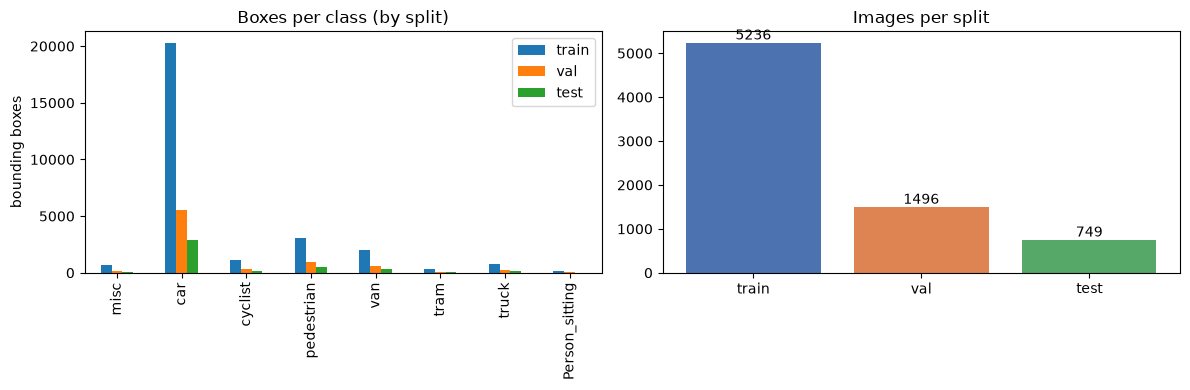

Total images: 7481


In [7]:
import matplotlib.pyplot as plt
import pandas as pd

dist = class_distribution(DATASET_DIR, class_names)
df = pd.DataFrame(dist).fillna(0).astype(int)
df["total"] = df.sum(axis=1)
display(df)

(OUTPUTS_DIR / "plots").mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[["train", "val", "test"]].plot(kind="bar", ax=ax[0], title="Boxes per class (by split)")
ax[0].set_ylabel("bounding boxes")
sizes = {s: len(list((DATASET_DIR / "images" / s).iterdir())) for s in ("train", "val", "test")}
ax[1].bar(sizes.keys(), sizes.values(), color=["#4c72b0", "#dd8452", "#55a868"])
ax[1].set_title("Images per split")
for i, v in enumerate(sizes.values()):
    ax[1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "plots" / "dataset_distribution.png", dpi=150)
plt.show()
print("Total images:", sum(sizes.values()))

## 6. Sample images with ground-truth boxes

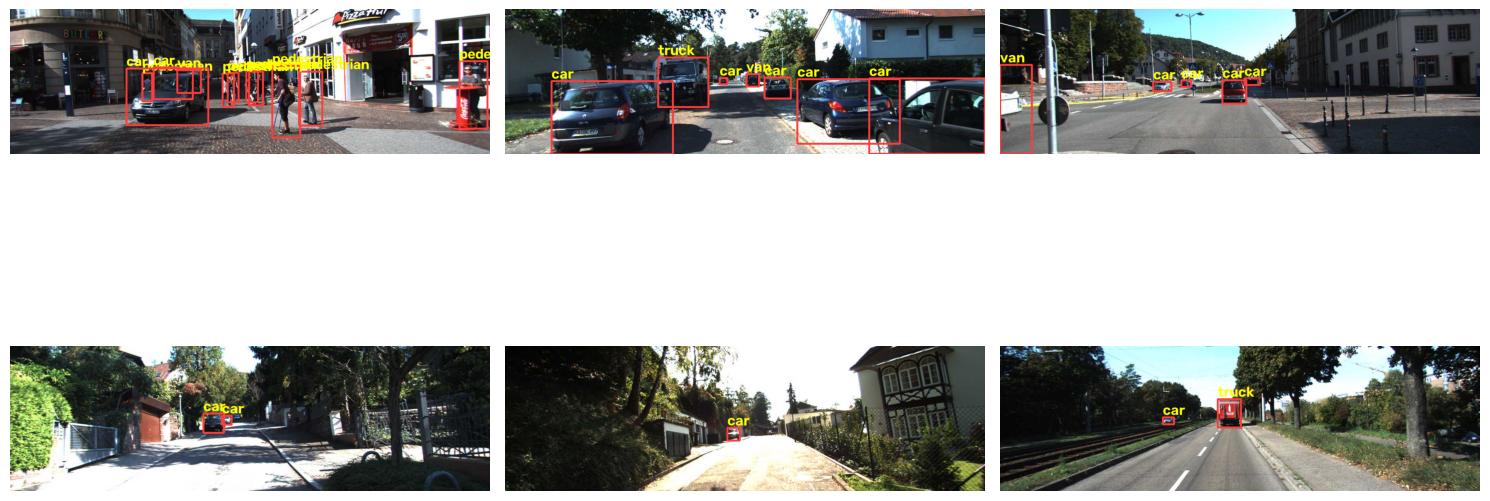

In [8]:
import random
import cv2

def draw_gt(img_path, lbl_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in lbl_path.read_text().splitlines():
        c, x, y, bw, bh = line.split()
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        p1, p2 = (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2))
        cv2.rectangle(img, p1, p2, (255, 60, 60), max(2, w // 300))
        cv2.putText(img, class_names[int(c)], (p1[0], max(p1[1] - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 1000), (255, 255, 0), 2)
    return img

train_imgs = sorted((DATASET_DIR / "images" / "train").iterdir())
random.Random(SEED).shuffle(train_imgs)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axes.ravel(), train_imgs[:6]):
    ax.imshow(draw_gt(p, DATASET_DIR / "labels" / "train" / f"{p.stem}.txt"))
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "plots" / "sample_ground_truth.png", dpi=120)
plt.show()

**Check by eye:** the names drawn above must match the animals. If a label
looks wrong, the class-name order is wrong - fix `class_names` before training.

Next: `02_model_training.ipynb`.